<a href="https://colab.research.google.com/github/luiseduaardo/credit-card-fraud-detection/blob/main/analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 💳 | Aplicação de Ensembles em detecção de fraudes em cartões de crédito

In [45]:
# Execute caso esteja usando Google Colab
system("git clone https://github.com/luiseduaardo/credit-card-fraud-detection")
setwd("credit-card-fraud-detection")

## Introdução

### Sobre o problema

Fraudes em cartões de crédito são uma classe de problemas no Setor Financeiro Nacional (SFN) que apresenta uma grande relevância dado o prejuízo às instituições financeiras e aos clientes, e detectá-las automaticamente é um problema clássico de classificação binária, onde cada transação pode ser classificada como legítima ou fraudulenta.

Existe uma dificuldade central nesse problema. As fraudes são raras, o que causa um forte desbalanceamento das classes. Um classificador treinado nessas condições tende a favorecer a classe majoritária e pode alcançar acurácia alta sem identificar quase nenhuma fraude, justamente o caso que mais importa.

Além disso, modelos isolados enfrentam outras limitações nesse cenário. Eles podem ser sensíveis a ruído, ter dificuldade de captar relações não lineares entre os atributos e deixar de detectar fraudes cujo comportamento se parece com o de transações normais.

### Sobre os ensembles

No Projeto 1, realizamos um estudo conceitual e estatístico a respeito dos métodos de *ensemble*, que consistem na combinação de vários modelos para obter um preditor mais completo do que qualquer um deles sozinho. Vimos que esses modelos podem ser classificados de diversas formas, dentre elas:

| Método | Tipo de ensemble | Como ocorre o treinamento? | Como combina as previsões? | Objetivo principal | Exemplos |
|---|---|---|---|---|---|
| **Bagging** | Homogêneo | Em paralelo, cada um sobre uma amostra *bootstrap* (sorteada com reposição) | Votação majoritária (classificação) ou média (regressão) | Reduzir a variância (*overfitting*) | Random Forest |
| **Boosting** | Homogêneo | Em sequência, cada novo modelo focado nos erros dos anteriores | Soma ponderada dos modelos, controlada pela taxa de aprendizado | Reduzir o viés (*underfitting*) | AdaBoost, XGBoost |
| **Stacking** | Heterogêneo | Em paralelo, modelos de tipos diferentes treinados com validação cruzada (k-fold) | Um meta-modelo usa as previsões dos modelos-base como atributos e toma a decisão final | Reduzir viés e variância, aproveitando os erros diferentes de cada modelo | Vários métodos de classificação |

O sucesso desses métodos em problemas que já foram aplicados na realidade motiva a aplicação nesse nosso problema. A nossa hipótese inicial levantada é que combinar modelos permite contornar as limitações de classificadores individuais em dados desbalanceados e melhorar a detecção da classe minoritária.


### Objetivos

Com essa análise, buscamos responder o seguinte:

Em um conjunto de transações de cartão de crédito com classes desbalanceadas, os métodos de ensemble (Bagging, Boosting e Stacking) detectam fraudes melhor do que modelos de classificação individuais? Qual desses métodos apresenta o melhor desempenho?

Para isso, pretendemos:

1. Explorar os dados para identificar quais características diferenciam transações fraudulentas das legítimas;
2. Validar estatisticamente, com testes de hipóteses, os padrões encontrados na análise exploratória;
3. Treinar modelos individuais de referência (*baseline*) e modelos de ensemble (Random Forest, XGBoost e Stacking);
4. Comparar os modelos com métricas adequadas.

### Descrição dos Dados

O dataset utilizado é o [Credit Card Fraud Detection](https://www.kaggle.com/datasets/miadul/credit-card-fraud-detection-dataset), que extraímos da plataforma Kaggle.

Esse conjunto de dados contém 10.000 transações simuladas de cartões de crédito, legítimas e fraudulentas, com 9 colunas de variáveis e uma de  variável-alvo, que é `is_fraud`.

O dataset possui o seguinte dicionário de dados:

| Variável | Tipo de variável | Descrição |
|---|---|---|
| `transaction_id` | Identificador | Código único da transação |
| `amount` | Numérica contínua | Valor da transação |
| `transaction_hour` | Numérica discreta | Hora do dia em que a transação ocorreu |
| `merchant_category` | Categórica | Tipo de estabelecimento |
| `foreign_transaction` | Binária | Indica se a transação é internacional |
| `location_mismatch` | Binária | Indica divergência entre o local de faturamento do cartão e o local da transação |
| `device_trust_score` | Numérica contínua | Pontuação de confiança do dispositivo usado na transação |
| `velocity_last_24h` | Numérica discreta | Número de transações feitas com o cartão nas últimas 24 horas |
| `cardholder_age` | Numérica discreta | Idade do titular do cartão |
| `is_fraud` | Binária | Variável-alvo, que indica 1 = fraude, 0 = legítima |

## Análise Exploratória de Dados

Nesta etapa, realizamos uma análise exploratória dos dados e de suas principais estatísticas, buscando compreender melhor a estrutura do conjunto de dados, identificar padrões e fazer observações iniciais sobre os dados. A partir dessa análise, conseguimos estabelecer uma visão geral das informações disponíveis que auxiliará na condução das próximas etapas. As análises realizadas nessa seção serão feitas com base no dataset extraído e armazenado em `data/credit_card_fraud_10k.csv`, anexo a este repositório.

Para executar o notebook corretamente, recomenda-se iniciá-lo a partir da raiz do repositório, utilizando um kernel **R** e tendo o pacote `ggplot2` instalado. Durante a execução de todo o projeto, usamos o Google Colab, que possui um kernel já integrado ao ambiente e uma série de pacotes utilitários instalados, como é o caso da biblioteca mencionada.

Configuração das visualizações gráficas:

In [46]:
# install.packages("ggplot2")   # No colab já é disponível sem instalação
library(ggplot2)

# Definição de paleta de cores e tema para visualizações
cores <- c("Legítima" = "#4C78A8", "Fraude" = "#E45756")
theme_set(
  theme_minimal(base_size = 12) +
    theme(plot.title = element_text(face = "bold"),
          plot.title.position = "plot",
          panel.grid.minor = element_blank(),
          strip.text = element_text(face = "bold"),
          legend.position = "top")
)
options(repr.plot.width = 10, repr.plot.height = 5)

### 2.1 Carregamento, tipos e qualidade

Realizamos o carregamento dos dados em uma estrutura para sua exploração e análise. Nessa etapa, buscamos identificar suas características iniciais, observando aspectos como as dimensões do conjunto de dados, os tipos de informação presentes em cada coluna e suas principais estatísticas descritivas. Além disso, avaliamos a qualidade dos dados, verificando a existência de valores ausentes e registros duplicados, buscando informações relevantes que possam ser consideradas em etapas posteriores.

#### Definição da população, amostra e variáveis

O conjunto de dados utilizado neste estudo contém 10.000 transações de cartão de crédito, sendo cada transação uma unidade de observação. Consideramos essas transações como a amostra disponível para análise, enquanto a população corresponde ao conjunto de transações que poderiam ser geradas pelo mesmo processo de origem dos dados, como dados oficiais do Sistema Financeiro Nacional, por exemplo.

Também é importante compreender os diferentes tipos de variáveis presentes no dataset, pois essa classificação influencia diretamente a forma como os dados serão analisados e visualizados da maneira mais adequada. Temos variáveis categóricas, como `merchant_category`, variáveis binárias, como `is_fraud` e `foreign_transaction`, além de variáveis numéricas, como `amount`, `transaction_hour`, `cardholder_age` e `velocity_last_24h`.

A variável `transaction_id` não será considerada nas análises estatísticas, pois serve apenas para identificar cada transação (chave identificadora). Já `device_trust_score`, apesar de estar armazenada como número inteiro, representa uma pontuação e será analisada como uma variável numérica contínua.

Numa visão geral, temos as seguintes variáveis:

| Tipo | Variáveis |
|---|---|
| Qualitativa nominal | `merchant_category` |
| Qualitativa binária | `is_fraud` (variável alvo), `foreign_transaction`, `location_mismatch` |
| Quantitativa discreta | `transaction_hour`, `velocity_last_24h`, `cardholder_age` |
| Quantitativa contínua | `amount`, `device_trust_score` |

#### Estrutura dos dados

In [47]:
caminho <- file.path("data", "credit_card_fraud_10k.csv")
dados <- read.csv(caminho, stringsAsFactors = FALSE)

In [48]:
cat("Dimensões:", nrow(dados), "linhas x", ncol(dados), "colunas\n\n")
str(dados)

Dimensões: 10000 linhas x 10 colunas

'data.frame':	10000 obs. of  10 variables:
 $ transaction_id     : int  1 2 3 4 5 6 7 8 9 10 ...
 $ amount             : num  84.5 541.8 237 164.3 30.5 ...
 $ transaction_hour   : int  22 3 17 4 15 13 18 13 8 5 ...
 $ merchant_category  : chr  "Electronics" "Travel" "Grocery" "Grocery" ...
 $ foreign_transaction: int  0 1 0 0 0 0 0 0 0 0 ...
 $ location_mismatch  : int  0 0 0 1 0 0 0 0 0 0 ...
 $ device_trust_score : int  66 87 49 72 79 90 48 68 80 59 ...
 $ velocity_last_24h  : int  3 1 1 3 0 2 1 1 0 1 ...
 $ cardholder_age     : int  40 64 61 34 44 46 28 40 21 34 ...
 $ is_fraud           : int  0 0 0 0 0 0 0 0 0 0 ...


In [49]:
head(dados)

,transaction_id,amount,transaction_hour,merchant_category,foreign_transaction,location_mismatch,device_trust_score,velocity_last_24h,cardholder_age,is_fraud
,<int>,<dbl>,<int>,<chr>,<int>,<int>,<int>,<int>,<int>,<int>
1,1,84.47,22,Electronics,0,0,66,3,40,0
2,2,541.82,3,Travel,1,0,87,1,64,0
3,3,237.01,17,Grocery,0,0,49,1,61,0
4,4,164.33,4,Grocery,0,1,72,3,34,0
5,5,30.53,15,Food,0,0,79,0,44,0
6,6,30.53,13,Clothing,0,0,90,2,46,0


In [50]:
summary(dados)

 transaction_id      amount        transaction_hour merchant_category
 Min.   :    1   Min.   :   0.00   Min.   : 0.00    Length   :10000  
 1st Qu.: 2501   1st Qu.:  50.91   1st Qu.: 6.00    N.unique :    5  
 Median : 5000   Median : 122.09   Median :12.00    N.blank  :    0  
 Mean   : 5000   Mean   : 175.95   Mean   :11.59    Min.nchar:    4  
 3rd Qu.: 7500   3rd Qu.: 242.48   3rd Qu.:18.00    Max.nchar:   11  
 Max.   :10000   Max.   :1471.04   Max.   :23.00                     
 foreign_transaction location_mismatch device_trust_score velocity_last_24h
 Min.   :0.0000      Min.   :0.0000    Min.   :25.0       Min.   :0.000    
 1st Qu.:0.0000      1st Qu.:0.0000    1st Qu.:43.0       1st Qu.:1.000    
 Median :0.0000      Median :0.0000    Median :62.0       Median :2.000    
 Mean   :0.0978      Mean   :0.0857    Mean   :61.8       Mean   :2.009    
 3rd Qu.:0.0000      3rd Qu.:0.0000    3rd Qu.:80.0       3rd Qu.:3.000    
 Max.   :1.0000      Max.   :1.0000    Max.   :99.0   

#### Qualidade dos dados

In [51]:
data.frame(
  verificacao = c("Valores ausentes", "Linhas duplicadas", "IDs duplicados"),
  total = c(sum(is.na(dados)), sum(duplicated(dados)), sum(duplicated(dados$transaction_id)))
)

verificacao,total
<chr>,<int>
Valores ausentes,0
Linhas duplicadas,0
IDs duplicados,0


No arquivo fornecido há 10.000 transações, sem valores ausentes, linhas repetidas ou IDs repetidos, o que nos leva a perceber que não é necessário realizar a imputação, deleção ou utilização de qualquer outra técnica de processamento dos dados na etapa atual. 

No entanto, isso ainda não significa que os dados não podem ser modificados ou que não sejam inconsistentes. Nas análises posteriores, realizaremos esse tipo de verificação para que restrições de domínio do problema ou estatísticas sejam solucionadas na etapa de pré-processamento.

#### Preparação dos tipos

Nesta etapa, realizamos alguns ajustes nas variáveis para facilitar a análise, mantendo as características para que os dados possam ser analisados estatisticamente e posteriormente consigam ser processados devidamento pelo algoritmo de machine learning.

Para isso, as variáveis categóricas são convertidas para o formato de rótulos mais intuitivos para representar seus valores. Também selecionamos as variáveis numéricas que serão exploradas e definimos nomes mais descritivos para sua apresentação nos gráficos. Por fim, estabelecemos os intervalos que serão utilizados na construção dos histogramas, considerando a distribuição e as características de cada variável.

In [52]:
# Variáveis qualitativas
dados$is_fraud <- factor(dados$is_fraud, levels = 0:1, labels = c("Legítima", "Fraude"))
dados$merchant_category <- factor(dados$merchant_category)
dados$foreign_transaction <- factor(dados$foreign_transaction, levels = 0:1, labels = c("Não", "Sim"))
dados$location_mismatch <- factor(dados$location_mismatch, levels = 0:1, labels = c("Não", "Sim"))

# Variáveis quantitativas
numericas <- c("amount", "transaction_hour", "device_trust_score",
               "velocity_last_24h", "cardholder_age")
rotulos <- c(amount = "Valor da transação",
             transaction_hour = "Hora da transação",
             device_trust_score = "Confiança do dispositivo",
             velocity_last_24h = "Transações em 24 h",
             cardholder_age = "Idade do titular")

# Classes de cada variável
quebras <- list(amount = "Sturges",
                transaction_hour = seq(-0.5, 23.5, 1),
                device_trust_score = seq(24, 99, 5),
                velocity_last_24h = seq(-0.5, 9.5, 1),
                cardholder_age = seq(17, 69, 4))

### 2.2 Análise univariada

Cada variável é analisada de acordo com suas características. Para as variáveis qualitativas, utilizamos tabelas de frequência e gráficos de barras. Já para as quantitativas, apresentamos tabelas com os valores observados ou agrupados em classes, além de histogramas para visualizar sua distribuição. Também calculamos medidas estatísticas que permitem compreender melhor os dados, considerando aspectos como tendência central, dispersão, posição e formato da distribuição.

Nas tabelas de frequência, `fi` representa a frequência absoluta e `fr` a frequência relativa. Quando a variável apresenta uma ordem natural entre seus valores, também são apresentadas as frequências acumuladas (`Fi` e `Fr (%)`).

#### Variável-alvo e variáveis qualitativas

In [53]:
# Monta a tabela de frequências
montar_tabela <- function(rotulos, fi, nome, acumulada = TRUE) {
  fi <- as.integer(fi)
  fr <- fi / sum(fi)
  tab <- data.frame(factor(rotulos, levels = unique(rotulos)), fi, round(fr, 4), round(100 * fr, 2))
  names(tab) <- c(nome, "fi", "fr", "fr (%)")
  if (acumulada) {
    tab$Fi <- cumsum(tab$fi)
    tab[["Fr (%)"]] <- round(100 * cumsum(fr), 2)
  }
  tab
}

# Para variáveis qualitativas ou quantitativas discretas
tabela_freq <- function(x, nome = "categoria", ordenar = FALSE, acumulada = TRUE) {
  fi <- table(x)
  if (ordenar) fi <- sort(fi, decreasing = TRUE)
  montar_tabela(names(fi), fi, nome, acumulada)
}

# Para variáveis quantitativas em classes
tabela_classes <- function(x, quebras, nome = "classe") {
  h <- hist(x, breaks = quebras, plot = FALSE)
  b <- h$breaks
  classe <- paste0("(", head(b, -1), ", ", tail(b, -1), "]")
  classe[1] <- sub("^\\(", "[", classe[1])
  montar_tabela(classe, h$counts, nome)
}

rotulo_barra <- function(fi, pct) {
  sprintf("%s (%s%%)", formatC(fi, big.mark = ".", decimal.mark = ",", format = "d"),
          formatC(pct, format = "f", digits = 2, decimal.mark = ","))
}

In [54]:
tab_alvo <- tabela_freq(dados$is_fraud, acumulada = FALSE)
tab_alvo

categoria,fi,fr,fr (%)
<fct>,<int>,<dbl>,<dbl>
Legítima,9849,0.9849,98.49
Fraude,151,0.0151,1.51


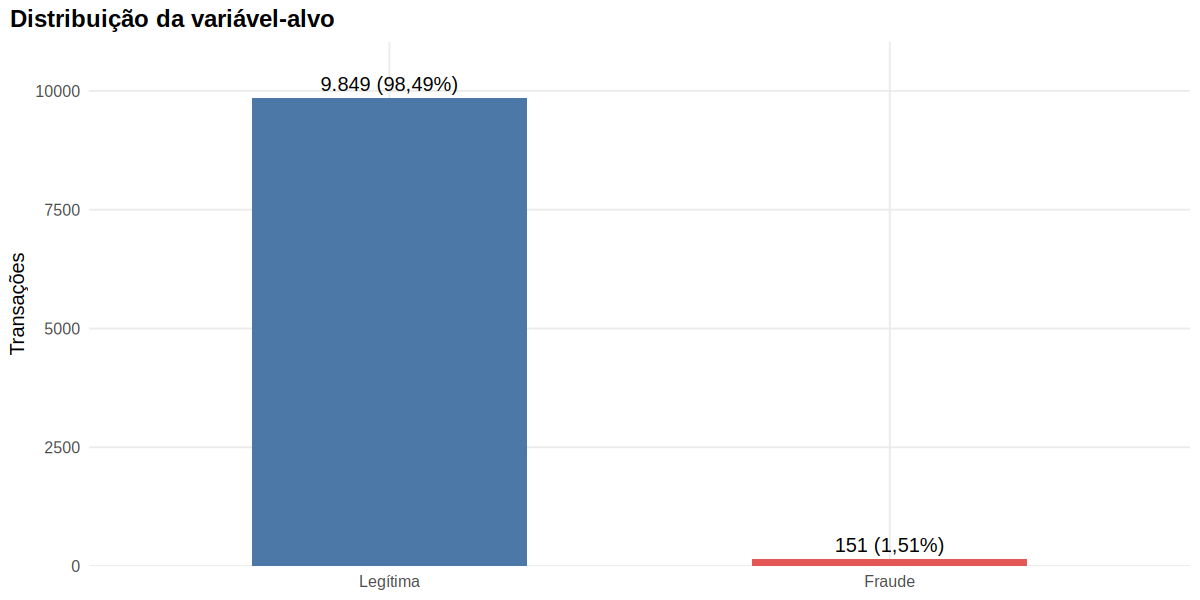

In [55]:
ggplot(tab_alvo, aes(categoria, fi, fill = categoria)) +
  geom_col(width = 0.55, show.legend = FALSE) +
  geom_text(aes(label = rotulo_barra(fi, `fr (%)`)), vjust = -0.5) +
  scale_fill_manual(values = cores) +
  scale_y_continuous(expand = expansion(mult = c(0, 0.12))) +
  labs(title = "Distribuição da variável-alvo", x = NULL, y = "Transações")

Do total de transações analisadas, **151 (1,51%) foram identificadas como fraudulentas**, enquanto as outras 9.849 (98,49%) foram classificadas como legítimas. Isso evidencia um desbalanceamento significativo entre as classes. 

Nesse cenário, utilizar apenas a acurácia para avaliar um modelo pode levar a interpretações equivocadas, já que um classificador que previsse todas as transações como legítimas já alcançaria 98,49% de acerto, mesmo sem identificar nenhuma fraude.

Por essa razão, é necessário avaliar a performance de um classificador conforme outras métricas de avaliação, como o *recall*, que pune significativamente a incidência de falsos negativos.

In [56]:
tab_cat <- tabela_freq(dados$merchant_category, ordenar = TRUE, acumulada = FALSE)
tab_cat

categoria,fi,fr,fr (%)
<fct>,<int>,<dbl>,<dbl>
Food,2093,0.2093,20.93
Clothing,2050,0.2050,20.50
Travel,1990,0.1990,19.90
Grocery,1944,0.1944,19.44
Electronics,1923,0.1923,19.23


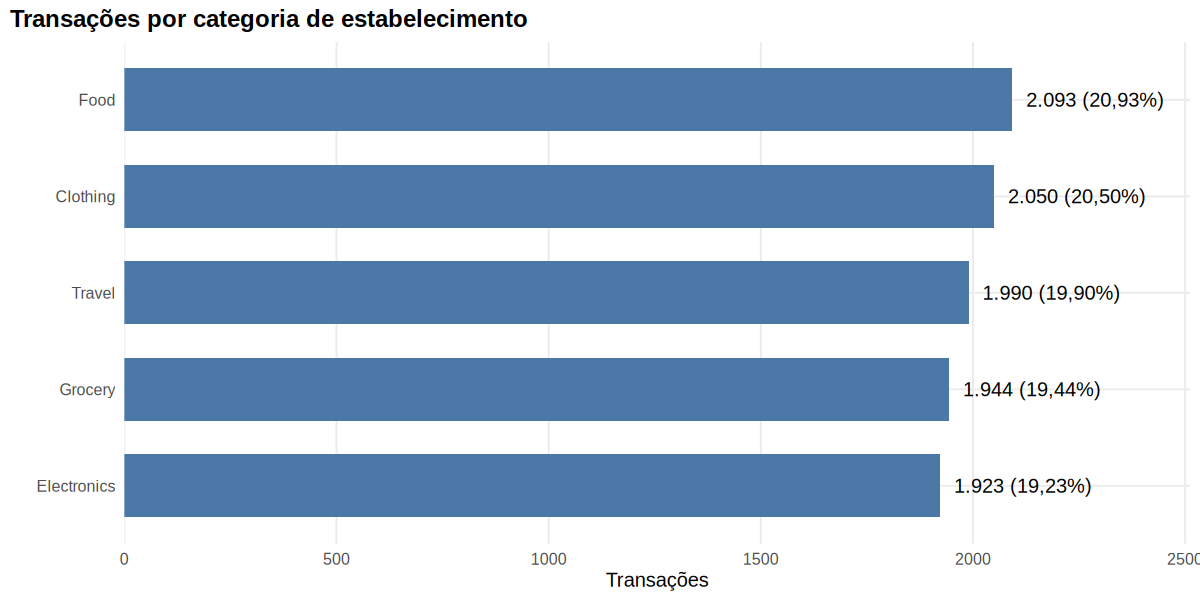

In [57]:
ggplot(tab_cat, aes(reorder(categoria, fi), fi)) +
  geom_col(fill = "#4C78A8", width = 0.65) +
  geom_text(aes(label = rotulo_barra(fi, `fr (%)`)), hjust = -0.1) +
  coord_flip() +
  scale_y_continuous(expand = expansion(mult = c(0, 0.2))) +
  labs(title = "Transações por categoria de estabelecimento", x = NULL, y = "Transações")

As cinco categorias de estabelecimentos apresentam uma distribuição bastante equilibrada, com participações entre 19% e 21% do total de transações. Isso indica que nenhuma categoria se destaca significativamente em relação às demais.

In [58]:
rbind(
  cbind(variavel = "foreign_transaction", tabela_freq(dados$foreign_transaction, acumulada = FALSE)),
  cbind(variavel = "location_mismatch", tabela_freq(dados$location_mismatch, acumulada = FALSE))
)

variavel,categoria,fi,fr,fr (%)
<chr>,<fct>,<int>,<dbl>,<dbl>
foreign_transaction,Não,9022,0.9022,90.22
foreign_transaction,Sim,978,0.0978,9.78
location_mismatch,Não,9143,0.9143,91.43
location_mismatch,Sim,857,0.0857,8.57


Por outro lado, os indicadores de transações internacionais e divergência de localização aparecem com menor frequência, representando, respectivamente, 9,78% e 8,57% dos registros. Esse comportamento mostra que essas duas características estão presentes em uma parcela menor das transações analisadas.

#### Variáveis quantitativas: distribuições de frequências

In [ ]:
tabela_freq(dados$velocity_last_24h, nome = "transações em 24 h")

transações em 24 h,fi,fr,fr (%),Fi,Fr (%)
<fct>,<int>,<dbl>,<dbl>,<int>,<dbl>
0,1378,0.1378,13.78,1378,13.78
1,2694,0.2694,26.94,4072,40.72
2,2662,0.2662,26.62,6734,67.34
3,1785,0.1785,17.85,8519,85.19
4,934,0.0934,9.34,9453,94.53
5,365,0.0365,3.65,9818,98.18
6,131,0.0131,1.31,9949,99.49
7,42,0.0042,0.42,9991,99.91
8,6,0.0006,0.06,9997,99.97


In [ ]:
faixa_hora <- cut(dados$transaction_hour, breaks = c(-1, 5, 11, 17, 23),
                  labels = c("00–05 h", "06–11 h", "12–17 h", "18–23 h"))
tabela_freq(faixa_hora, nome = "faixa horária")

faixa horária,fi,fr,fr (%),Fi,Fr (%)
<fct>,<int>,<dbl>,<dbl>,<int>,<dbl>
00–05 h,2455,0.2455,24.55,2455,24.55
06–11 h,2431,0.2431,24.31,4886,48.86
12–17 h,2577,0.2577,25.77,7463,74.63
18–23 h,2537,0.2537,25.37,10000,100.00


In [61]:
tabela_classes(dados$cardholder_age, quebras$cardholder_age, nome = "idade (anos)")

idade (anos),fi,fr,fr (%),Fi,Fr (%)
<fct>,<int>,<dbl>,<dbl>,<int>,<dbl>
"[17, 21]",754,0.0754,7.54,754,7.54
"(21, 25]",782,0.0782,7.82,1536,15.36
"(25, 29]",779,0.0779,7.79,2315,23.15
"(29, 33]",779,0.0779,7.79,3094,30.94
"(33, 37]",769,0.0769,7.69,3863,38.63
"(37, 41]",748,0.0748,7.48,4611,46.11
"(41, 45]",777,0.0777,7.77,5388,53.88
"(45, 49]",778,0.0778,7.78,6166,61.66
"(49, 53]",795,0.0795,7.95,6961,69.61


In [62]:
tabela_classes(dados$device_trust_score, quebras$device_trust_score, nome = "score do dispositivo")

score do dispositivo,fi,fr,fr (%),Fi,Fr (%)
<fct>,<int>,<dbl>,<dbl>,<int>,<dbl>
"[24, 29]",681,0.0681,6.81,681,6.81
"(29, 34]",639,0.0639,6.39,1320,13.20
"(34, 39]",635,0.0635,6.35,1955,19.55
"(39, 44]",699,0.0699,6.99,2654,26.54
"(44, 49]",705,0.0705,7.05,3359,33.59
"(49, 54]",668,0.0668,6.68,4027,40.27
"(54, 59]",669,0.0669,6.69,4696,46.96
"(59, 64]",680,0.0680,6.80,5376,53.76
"(64, 69]",695,0.0695,6.95,6071,60.71


In [63]:
tabela_classes(dados$amount, quebras$amount, nome = "valor")

valor,fi,fr,fr (%),Fi,Fr (%)
<fct>,<int>,<dbl>,<dbl>,<int>,<dbl>
"[0, 100]",4338,0.4338,43.38,4338,43.38
"(100, 200]",2475,0.2475,24.75,6813,68.13
"(200, 300]",1364,0.1364,13.64,8177,81.77
"(300, 400]",779,0.0779,7.79,8956,89.56
"(400, 500]",433,0.0433,4.33,9389,93.89
"(500, 600]",280,0.0280,2.80,9669,96.69
"(600, 700]",150,0.0150,1.50,9819,98.19
"(700, 800]",83,0.0083,0.83,9902,99.02
"(800, 900]",43,0.0043,0.43,9945,99.45


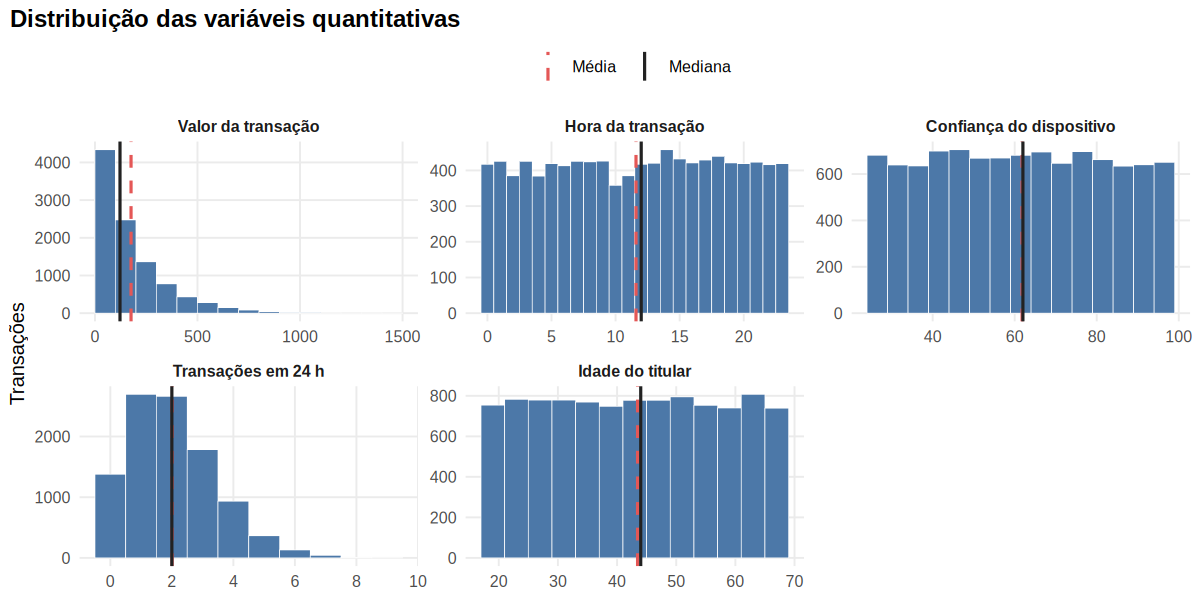

In [94]:
ordem_rotulos <- unname(rotulos[numericas])

hist_df <- function(v) {
  h <- hist(dados[[v]], breaks = quebras[[v]], plot = FALSE)
  data.frame(variavel = rotulos[[v]], x = h$mids, n = h$counts, largura = diff(h$breaks))
}
referencias <- function(v) {
  data.frame(variavel = rotulos[[v]], medida = c("Média", "Mediana"),
             valor = c(mean(dados[[v]]), median(dados[[v]])))
}
hists <- do.call(rbind, lapply(numericas, hist_df))
refs  <- do.call(rbind, lapply(numericas, referencias))
hists$variavel <- factor(hists$variavel, levels = ordem_rotulos)
refs$variavel  <- factor(refs$variavel,  levels = ordem_rotulos)

ggplot(hists, aes(x, n)) +
  geom_rect(aes(xmin = x - largura / 2, xmax = x + largura / 2, ymin = 0, ymax = n),
            fill = "#4C78A8", color = "white", linewidth = 0.2) +
  geom_vline(data = refs, aes(xintercept = valor, color = medida, linetype = medida), linewidth = 0.9) +
  facet_wrap(~ variavel, scales = "free", ncol = 3) +
  scale_x_continuous(breaks = scales::pretty_breaks(n = 5)) +
  scale_color_manual(values = c("Média" = "#E45756", "Mediana" = "#222222"), name = NULL) +
  scale_linetype_manual(values = c("Média" = "dashed", "Mediana" = "solid"), name = NULL) +
  labs(title = "Distribuição das variáveis quantitativas", x = NULL, y = "Transações")

<a id="distribuicoes-frequencias"></a>

Ao observar a distribuição das variáveis quantitativas, percebemos comportamentos diferentes entre elas. As variáveis `transaction_hour`, `device_trust_score` e `cardholder_age` apresentam distribuições relativamente uniformes, com frequências semelhantes entre os valores observados e médias próximas às medianas.

Já a variável `amount` apresenta uma concentração de transações em valores mais baixos, com uma distribuição assimétrica à direita. Cerca de 43,38% das transações possuem valores de até 100, enquanto 81,77% não ultrapassam 300. Apesar dessa concentração, existem registros que chegam a 1.471, fazendo com que a média fique acima da mediana.

Um comportamento semelhante ocorre com `velocity_last_24h`, cuja distribuição também apresenta uma cauda à direita. Aproximadamente 40,72% das transações possuem zero ou uma operação nas últimas 24 horas, enquanto apenas 5,47% apresentam cinco ou mais operações.

Conseguimos verificar todos esses comportamentos posteriormente no cálculo das medidas de assimetria e curtose.

#### Medidas resumo das variáveis quantitativas

Para complementar a análise das distribuições, calculamos medidas estatísticas que ajudam a compreender melhor o comportamento de cada variável. São consideradas medidas de tendência central, dispersão, posição e formato da distribuição (assimetria e a curtose).

In [85]:
# Aplica uma função a cada variável quantitativa
resumo_por_variavel <- function(f, digitos = 2) {
  tab <- do.call(rbind, lapply(numericas, function(v) data.frame(variavel = v, f(dados[[v]]))))
  tab[] <- lapply(tab, function(col) if (is.numeric(col)) round(col, digitos) else col)
  tab
}

##### Medidas de centro

In [88]:
# Função para cálculo da moda
moda <- function(x) as.numeric(names(which.max(table(x))))

In [87]:
resumo_por_variavel(function(x) data.frame(
  n = length(x),
  media = mean(x),
  mediana = median(x),
  moda = if (is.integer(x)) moda(x) else NA  # sem sentido para valores contínuos
))

variavel,n,media,mediana,moda
<chr>,<dbl>,<dbl>,<dbl>,<dbl>
amount,10000,175.95,122.1,NA
transaction_hour,10000,11.59,12.0,14
device_trust_score,10000,61.80,62.0,45
velocity_last_24h,10000,2.01,2.0,1
cardholder_age,10000,43.47,44.0,29


Na variável `amount`, observamos uma diferença considerável entre a média (175,95) e a mediana (122,10). Isso acontece porque algumas transações apresentam valores mais elevados, fazendo com que a média aumente. Nesse caso, a mediana representa melhor o valor típico das transações. Para as demais variáveis, média e mediana apresentam valores mais próximos.

A moda foi considerada apenas para as variáveis com valores inteiros. Entretanto, para `transaction_hour`, `device_trust_score` e `cardholder_age`, essa medida não oferece informações tão relevantes, uma vez que suas distribuições são relativamente uniformes. Em `velocity_last_24h`, a moda corresponde a 1 transação.

##### Medidas de dispersão

In [67]:
resumo_por_variavel(function(x) data.frame(
  amplitude = diff(range(x)),
  variancia = var(x),
  desvio_padrao = sd(x),
  cv_pct = 100 * sd(x) / mean(x),
  iiq = IQR(x)
))

variavel,amplitude,variancia,desvio_padrao,cv_pct,iiq
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
amount,1471.04,30762.64,175.39,99.68,191.58
transaction_hour,23.00,47.92,6.92,59.71,12.00
device_trust_score,74.00,461.69,21.49,34.77,37.00
velocity_last_24h,9.00,2.05,1.43,71.31,2.00
cardholder_age,51.00,224.37,14.98,34.46,26.00


A variável `amount` apresenta um desvio padrão de 175,39, valor bastante próximo de sua média (175,95). Isso resulta em um coeficiente de variação de 99,7%, o maior entre as variáveis analisadas, indicando uma dispersão elevada em relação à média. O coeficiente de variação permite comparar a variabilidade entre variáveis que possuem escalas ou unidades diferentes, desde que sejam medidas em escalas com zero absoluto. Por esse motivo, não é adequado utilizá-lo para `transaction_hour`.

Também observamos uma grande amplitude em `amount` (1.471,04), influenciada pela diferença entre os valores mínimo e máximo. Como essa medida é bastante sensível aos extremos, o intervalo interquartil (191,58) oferece uma visão complementar da dispersão, pois considera apenas a faixa central de 50% das transações.

##### Medidas de posição

In [68]:
resumo_por_variavel(function(x) {
  p <- quantile(x, c(0.25, 0.75, 0.90, 0.95, 0.99), names = FALSE)
  data.frame(minimo = min(x), q1 = p[1], q3 = p[2], p90 = p[3], p95 = p[4], p99 = p[5], maximo = max(x))
})

variavel,minimo,q1,q3,p90,p95,p99,maximo
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
amount,0,50.91,242.48,406.89,530.21,796.32,1471.04
transaction_hour,0,6.00,18.00,21.00,22.00,23.00,23.00
device_trust_score,25,43.00,80.00,92.00,96.00,99.00,99.00
velocity_last_24h,0,1.00,3.00,4.00,5.00,6.00,9.00
cardholder_age,18,30.00,56.00,64.00,67.00,69.00,69.00


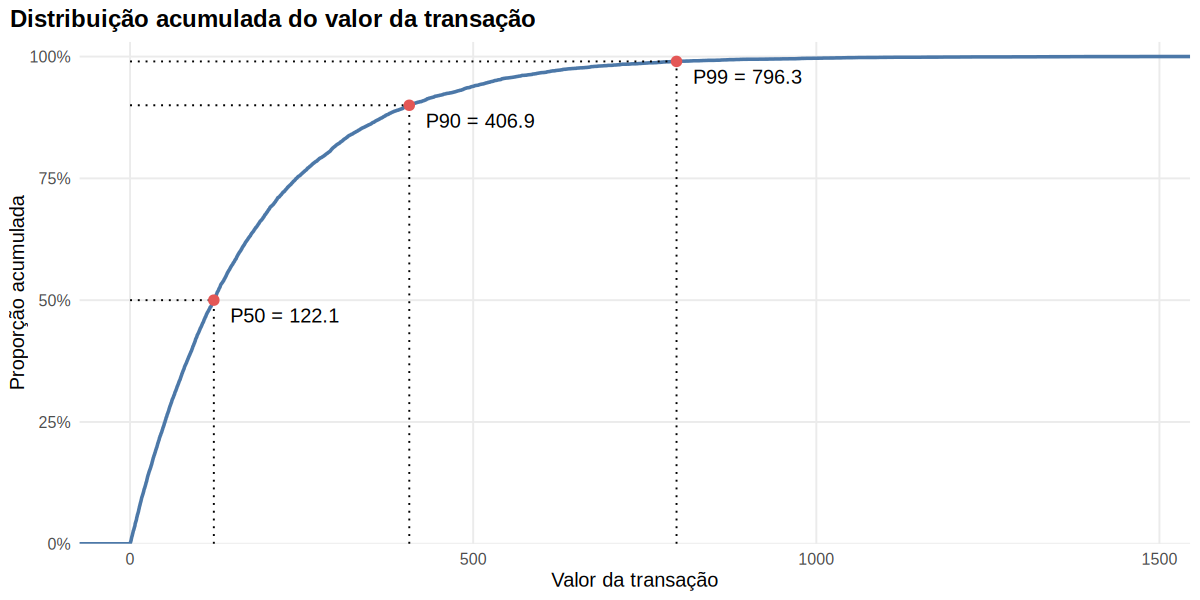

In [ ]:
pontos <- data.frame(prob = c(0.50, 0.90, 0.99),
                     valor = quantile(dados$amount, c(0.50, 0.90, 0.99), names = FALSE))

ggplot(dados, aes(amount)) +
  stat_ecdf(geom = "step", color = "#4C78A8", linewidth = 1) +
  geom_segment(data = pontos, aes(x = 0, xend = valor, y = prob, yend = prob), linetype = "dotted") +
  geom_segment(data = pontos, aes(x = valor, xend = valor, y = 0, yend = prob), linetype = "dotted") +
  geom_point(data = pontos, aes(valor, prob), color = "#E45756", size = 2.5) +
  geom_text(data = pontos, aes(valor, prob, label = paste0("P", prob * 100, " = ", round(valor, 1))),
            hjust = -0.15, vjust = 1.6) +
  scale_y_continuous(labels = scales::percent, expand = expansion(mult = c(0, 0.03))) +
  labs(title = "Distribuição acumulada do valor da transação",
       x = "Valor da transação", y = "Proporção acumulada")

Na variável `amount`, observamos que 99% das transações apresentam valores inferiores a 796,32, enquanto o maior valor registrado é 1.471,04. Essa diferença mostra que existem algumas transações com valores bastante elevados, reforçando a presença de uma cauda mais longa à direita na distribuição. Os percentis ajudam a visualizar como esses valores se comportam ao longo da distribuição, especialmente em sua parte final.

Na sequência, utilizamos o critério de Tukey, que usa o intervalo inter-quartil para identificar possíveis valores atípicos (*outliers*), considerando como limites os valores abaixo de $\text{Q1} − 1.5 \cdot \text{IIQ}$ ou acima de $\text{Q3} + 1.5 \cdot \text{IIQ}$.

In [89]:
# Valores fora do intervalo interquartil
resumo_por_variavel(function(x) {
  q <- quantile(x, c(0.25, 0.75), names = FALSE)
  lim <- c(q[1] - 1.5 * diff(q), q[2] + 1.5 * diff(q))
  fora <- sum(x < lim[1] | x > lim[2])
  data.frame(limite_inf = lim[1], limite_sup = lim[2], n_atipicos = fora, pct_atipicos = 100 * fora / length(x))
})

variavel,limite_inf,limite_sup,n_atipicos,pct_atipicos
<chr>,<dbl>,<dbl>,<dbl>,<dbl>
amount,-236.46,529.84,501,5.01
transaction_hour,-12.00,36.00,0,0.00
device_trust_score,-12.50,135.50,0,0.00
velocity_last_24h,-2.00,6.00,51,0.51
cardholder_age,-9.00,95.00,0,0.00


Foram identificados 501 valores atípicos em `amount` (5,01% dos registros) e 51 em `velocity_last_24h` (0,51%). Nas demais variáveis, não foram encontrados valores que ultrapassassem os limites definidos pelo critério de Tukey.

Entretanto, esses registros não serão removidos da análise, pois valores elevados de transação ou uma frequência incomum de operações podem representar justamente comportamentos relevantes para a identificação de possíveis fraudes. Portanto, decidimos preservá-los para as próximas etapas.

Conseguimos visualizar esses *outliers* graficamente abaixo:

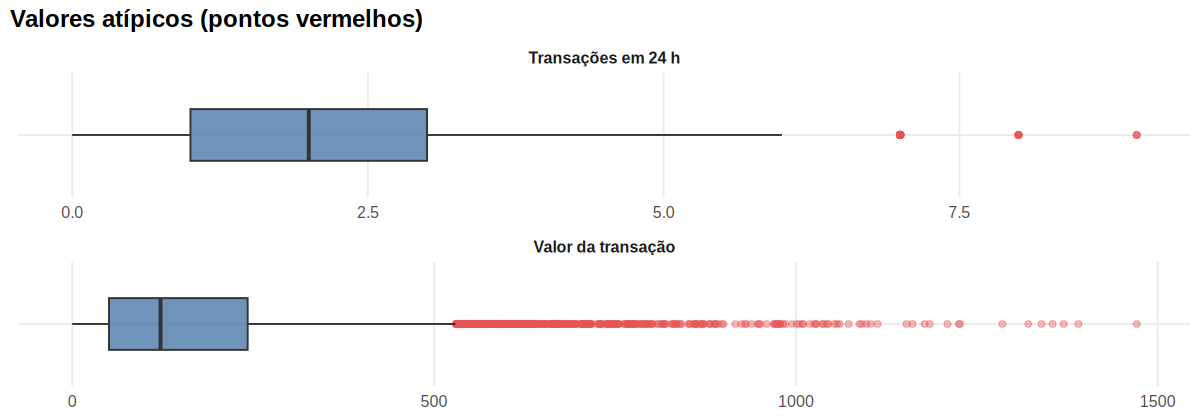

In [71]:
options(repr.plot.height = 3.5)

atipicas <- rbind(data.frame(variavel = "Valor da transação", valor = dados$amount),
                  data.frame(variavel = "Transações em 24 h", valor = dados$velocity_last_24h))

ggplot(atipicas, aes(valor, "")) +
  geom_boxplot(fill = "#4C78A8", alpha = 0.8, width = 0.5, outlier.color = "#E45756", outlier.alpha = 0.4) +
  facet_wrap(~ variavel, scales = "free_x", ncol = 1) +
  labs(title = "Valores atípicos (pontos vermelhos)", x = NULL, y = NULL)

options(repr.plot.height = 5)

##### Assimetria e curtose

A assimetria indica o grau e a direção da falta de simetria de uma distribuição. Valores positivos indicam uma cauda mais longa à direita, enquanto valores negativos indicam uma cauda mais longa à esquerda. Valores próximos de zero sugerem uma distribuição aproximadamente simétrica.

A curtose, por sua vez, está relacionada ao peso das caudas da distribuição em comparação com a normal e ao achatamento da curva. Na curtose em excesso, valores positivos indicam maior peso nas caudas (*leptocúrtica*), enquanto valores negativos indicam caudas mais leves (*platicúrtica*). Valores próximos de zero correspondem à referência *mesocúrtica*.

Como referência prática, consideramos valores absolutos de assimetria inferiores a $0.5$ como indicativo de distribuição aproximadamente simétrica. Para a curtose, valores absolutos inferiores a $0.5$ indicam um comportamento próximo ao da distribuição normal nesse aspecto.

In [91]:
# Definindo as funções de assimetria e curtose
assimetria <- function(x) mean((x - mean(x))^3) / mean((x - mean(x))^2)^1.5
curtose <- function(x) mean((x - mean(x))^4) / mean((x - mean(x))^2)^2 - 3

In [92]:
forma <- resumo_por_variavel(function(x) data.frame(assimetria = assimetria(x), curtose = curtose(x)), digitos = 3)
forma$tipo_assimetria <- cut(forma$assimetria, c(-Inf, -1, -0.5, 0.5, 1, Inf),
  labels = c("esquerda forte", "esquerda moderada", "aprox. simétrica", "direita moderada", "direita forte"))
forma$tipo_curtose <- cut(forma$curtose, c(-Inf, -0.5, 0.5, Inf),
  labels = c("platicúrtica", "mesocúrtica", "leptocúrtica"))
forma

variavel,assimetria,curtose,tipo_assimetria,tipo_curtose
<chr>,<dbl>,<dbl>,<fct>,<fct>
amount,1.919,5.115,direita forte,leptocúrtica
transaction_hour,-0.027,-1.206,aprox. simétrica,platicúrtica
device_trust_score,0.011,-1.180,aprox. simétrica,platicúrtica
velocity_last_24h,0.708,0.445,direita moderada,mesocúrtica
cardholder_age,0.004,-1.197,aprox. simétrica,platicúrtica


Aqui, conseguimos confirmar o comportamento que havíamos verificado anteriormente nos [histogramas para cada variável](#distribuicoes-frequencias)

As variáveis `transaction_hour`, `device_trust_score` e `cardholder_age` têm assimetria próxima de zero e curtose em torno de −1,2, valor característico da curtose em excesso de uma distribuição uniforme. Esse resultado é coerente com o formato dos histogramas.

A variável `amount` apresenta forte assimetria à direita ($g_1 = 1.92$) e caudas pesadas ($g_2 = 5.12$), confirmando numericamente. Diante disso, essa variável merece atenção especial, já que como sua distribuição é bastante assimétrica e apresenta caudas pesadas, medidas como a mediana e o intervalo interquartil (IIQ), são mais adequadas para descrever sua distribuição.

Assim como também verificado anteriormente, `velocity_last_24h` também possui uma assimetria à direita, mais leve que `amount`, dado a assimetria à direita de $g_1 = 0.708$ e uma curtose razoável no valor de $g_2 = 0.445$.

### 2.3 Relações com a classe e entre variáveis

Uma vez calculadas as estatísticas das variáveis de maneira individual, nessa etapa, buscamos explorar as diferenças entre transações fraudulentas e legítimas, analisando como as variáveis se comportam em cada grupo. Também investigamos possíveis associações entre as variáveis, com o objetivo de identificar padrões que possam contribuir para a compreensão dos dados e a detecção de fraudes.

Vale ressaltar que como a etapa atual é exploratória, possíveis correlações encontradas entre variáveis não vão indicar uma relação de causalidade, o que é comumente confundido e pode enviezar a atual análise. Uma vez que tivermos uma análise mais completa dos dados, poderemos levantar hipóteses a serem confirmadas pela validação estatística posterior.

#### Taxa de fraude por grupo

In [95]:
dados$madrugada <- factor(ifelse(dados$transaction_hour < 6, "00–05 h", "06–23 h"),
                          levels = c("06–23 h", "00–05 h"))

taxas <- function(variavel, rotulo) {
  tab <- table(dados[[variavel]], dados$is_fraud)
  data.frame(variavel = rotulo, grupo = factor(rownames(tab), levels = rownames(tab)), n = as.integer(rowSums(tab)),
             fraudes = as.integer(tab[, "Fraude"]),
             taxa_pct = round(100 * tab[, "Fraude"] / rowSums(tab), 2), row.names = NULL)
}
tab_taxas <- rbind(
  taxas("merchant_category", "Categoria do estabelecimento"),
  taxas("foreign_transaction", "Transação internacional"),
  taxas("location_mismatch", "Divergência de localização"),
  taxas("madrugada", "Horário (exploratório)")
)
tab_taxas

variavel,grupo,n,fraudes,taxa_pct
<chr>,<fct>,<int>,<int>,<dbl>
Categoria do estabelecimento,Clothing,2050,24,1.17
Categoria do estabelecimento,Electronics,1923,24,1.25
Categoria do estabelecimento,Food,2093,35,1.67
Categoria do estabelecimento,Grocery,1944,39,2.01
Categoria do estabelecimento,Travel,1990,29,1.46
Transação internacional,Não,9022,69,0.76
Transação internacional,Sim,978,82,8.38
Divergência de localização,Não,9143,79,0.86
Divergência de localização,Sim,857,72,8.40


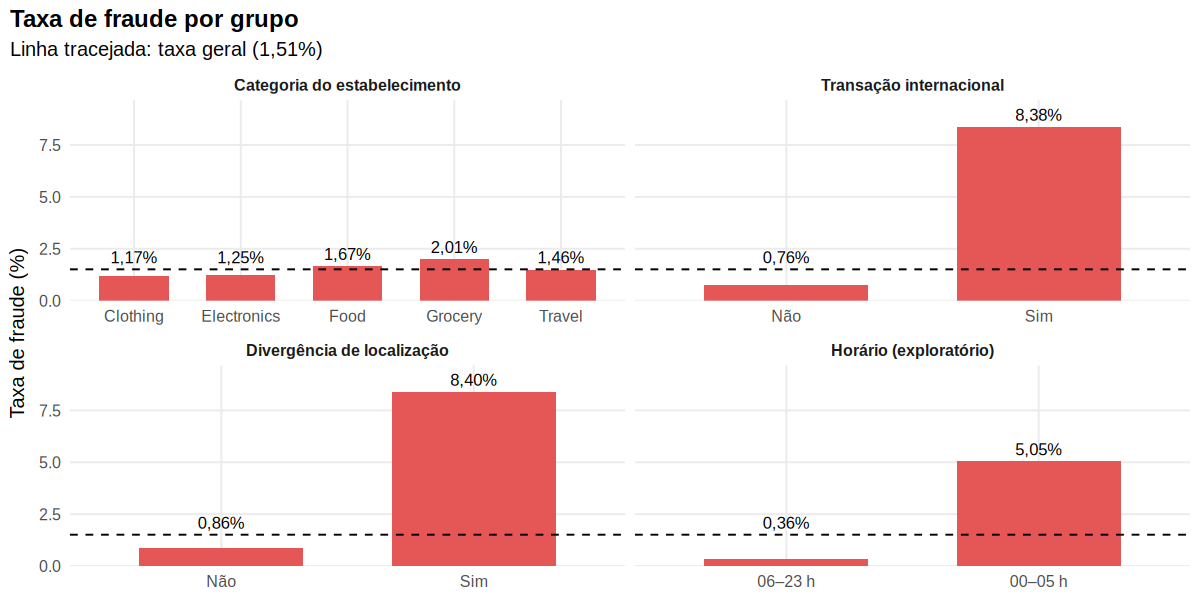

In [96]:
taxa_geral <- 100 * mean(dados$is_fraud == "Fraude")
tab_taxas$variavel <- factor(tab_taxas$variavel, levels = unique(tab_taxas$variavel))

ggplot(tab_taxas, aes(grupo, taxa_pct)) +
  geom_col(fill = "#E45756", width = 0.65) +
  geom_hline(yintercept = taxa_geral, linetype = "dashed") +
  geom_text(aes(y = pmax(taxa_pct, taxa_geral),
                label = paste0(formatC(taxa_pct, format = "f", digits = 2, decimal.mark = ","), "%")),
            vjust = -0.5, size = 3.5) +
  facet_wrap(~ variavel, scales = "free_x", ncol = 2) +
  scale_y_continuous(expand = expansion(mult = c(0, 0.15))) +
  labs(title = "Taxa de fraude por grupo",
       subtitle = paste0("Linha tracejada: taxa geral (",
                         formatC(taxa_geral, format = "f", digits = 2, decimal.mark = ","), "%)"),
       x = NULL, y = "Taxa de fraude (%)")

As taxas de fraude são aproximadamente 11 vezes maiores nas transações internacionais do que nas nacionais (8,38% contra 0,76%). O mesmo padrão aparece nas transações com divergência de localização, cuja taxa de fraude é cerca de 10 vezes maior (8,40% contra 0,86%).

Já a categoria do estabelecimento apresenta diferenças menores, com taxas que variam de 1,17% em `Clothing` a 2,01% em `Grocery`. Também analisamos a faixa de horário entre 00h e 05h, selecionada após a observação dos dados.

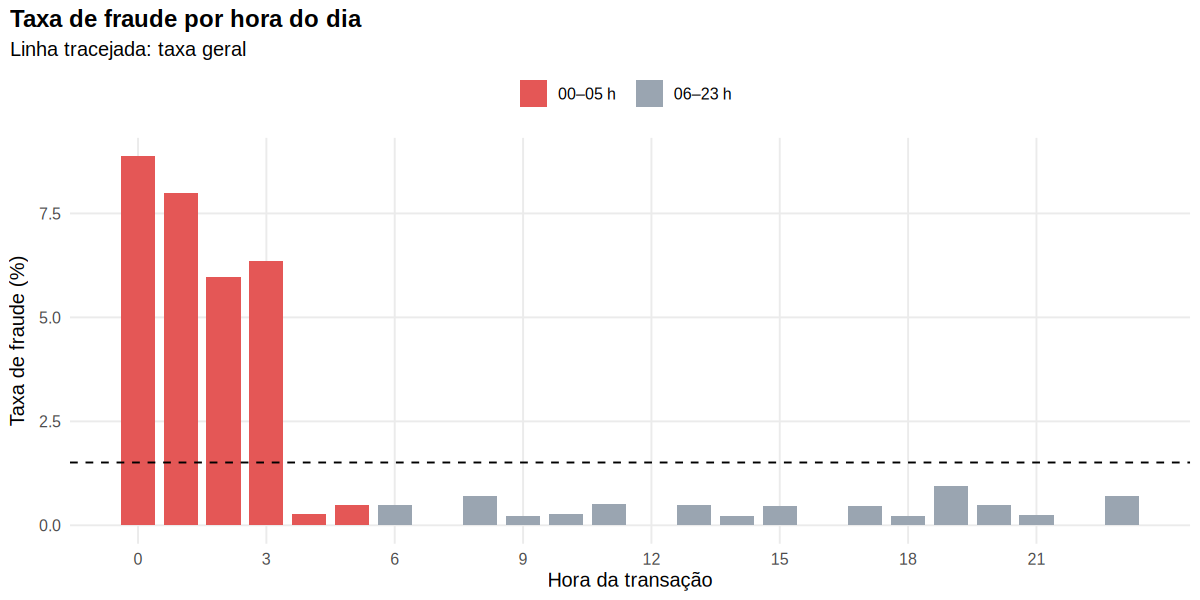

In [75]:
por_hora <- data.frame(
  hora = 0:23,
  taxa_pct = sapply(0:23, function(h) 100 * mean(dados$is_fraud[dados$transaction_hour == h] == "Fraude"))
)
por_hora$faixa <- ifelse(por_hora$hora < 6, "00–05 h", "06–23 h")

ggplot(por_hora, aes(hora, taxa_pct, fill = faixa)) +
  geom_col(width = 0.8) +
  geom_hline(yintercept = taxa_geral, linetype = "dashed") +
  scale_fill_manual(values = c("00–05 h" = "#E45756", "06–23 h" = "#9AA5B1"), name = NULL) +
  scale_x_continuous(breaks = seq(0, 23, 3)) +
  labs(title = "Taxa de fraude por hora do dia", subtitle = "Linha tracejada: taxa geral",
       x = "Hora da transação", y = "Taxa de fraude (%)")

O gráfico por hora permite identificar melhor esse padrão, já que entre 0h e 3h, as taxas de fraude ficam entre 6% e 9%, enquanto às 4h e 5h já retornam a níveis próximos aos observados no restante do dia.

Nesse intervalo de 0h a 3h, foram registradas 121 das 151 fraudes, o que corresponde a uma taxa de 7,32% entre 1.652 transações. Nas demais horas, a taxa cai para 0,36%.

Isso mostra que a faixa de 00h a 05h utilizada na tabela anterior é relativamente ampla, pois inclui duas horas sem o mesmo aumento na taxa de fraude. Com isso, o contraste entre os períodos acaba sendo menor do que quando consideramos apenas o intervalo de 0h a 3h.

#### Variáveis quantitativas por classe

In [76]:
resumo_classe <- do.call(rbind, lapply(numericas, function(v) {
  do.call(rbind, lapply(levels(dados$is_fraud), function(g) {
    x <- dados[[v]][dados$is_fraud == g]
    data.frame(variavel = v, classe = g, n = length(x), media = mean(x), mediana = median(x),
               desvio_padrao = sd(x), q1 = unname(quantile(x, 0.25)), q3 = unname(quantile(x, 0.75)))
  }))
}))
resumo_classe[] <- lapply(resumo_classe, function(col) if (is.numeric(col)) round(col, 2) else col)
resumo_classe

variavel,classe,n,media,mediana,desvio_padrao,q1,q3
<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
amount,Legítima,9849,175.33,122.11,173.99,50.99,241.65
amount,Fraude,151,216.18,118.94,248.12,41.53,341.70
transaction_hour,Legítima,9849,11.71,12.00,6.87,6.00,18.00
transaction_hour,Fraude,151,3.84,2.00,5.80,1.00,3.00
device_trust_score,Legítima,9849,62.17,62.00,21.35,44.00,80.00
device_trust_score,Fraude,151,37.87,32.00,16.18,28.50,38.00
velocity_last_24h,Legítima,9849,1.99,2.00,1.42,1.00,3.00
velocity_last_24h,Fraude,151,3.21,3.00,1.95,2.00,5.00
cardholder_age,Legítima,9849,43.47,44.00,14.99,30.00,56.00


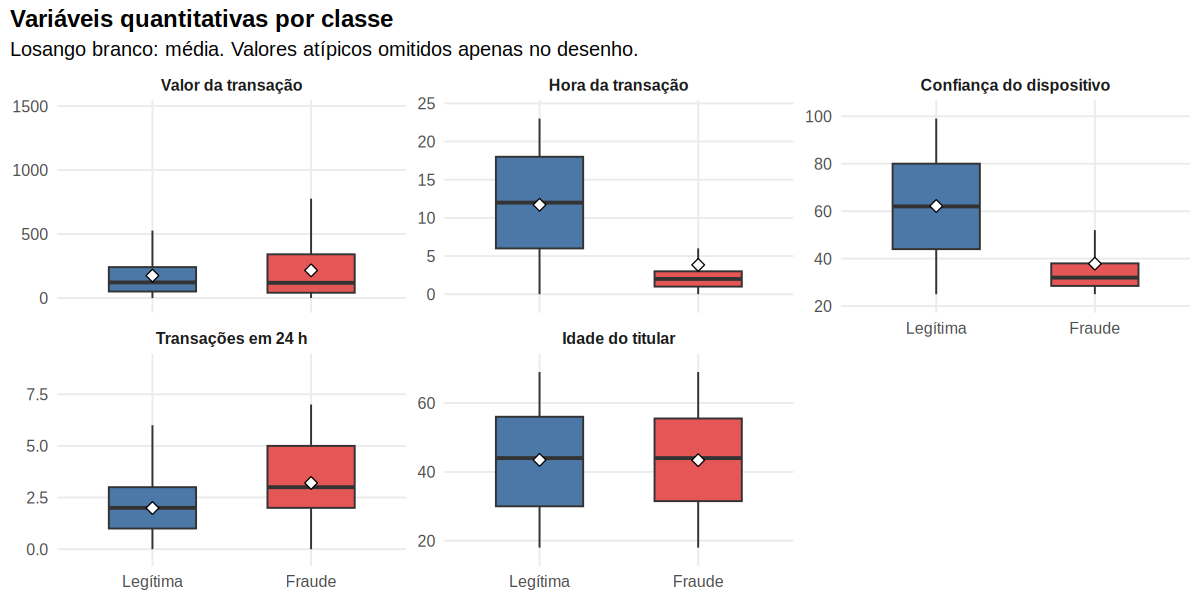

In [77]:
long <- do.call(rbind, lapply(numericas, function(v) {
  data.frame(variavel = factor(rotulos[[v]], levels = ordem_rotulos),
             classe = dados$is_fraud, valor = dados[[v]])
}))

# Eixo ajustado aos bigodes: valores extremos ficam fora do desenho, mas nenhum dado é removido
limites <- do.call(rbind, lapply(split(long, long$variavel), function(d) {
  b <- unlist(lapply(split(d$valor, d$classe), function(x) boxplot.stats(x)$stats[c(1, 5)]))
  folga <- 0.05 * diff(range(b))
  data.frame(variavel = d$variavel[1], valor = c(min(b) - folga, max(b) + folga))
}))

ggplot(long, aes(classe, valor, fill = classe)) +
  geom_boxplot(outlier.shape = NA, width = 0.55, show.legend = FALSE) +
  stat_summary(fun = mean, geom = "point", shape = 23, size = 2.5, fill = "white") +
  geom_blank(data = limites, aes(x = NULL, fill = NULL)) +
  facet_wrap(~ variavel, scales = "free_y", ncol = 3) +
  scale_fill_manual(values = cores) +
  labs(title = "Variáveis quantitativas por classe",
       subtitle = "Losango branco: média. Valores atípicos omitidos apenas no desenho.",
       x = NULL, y = NULL)

As transações fraudulentas ocorrem, em geral, mais cedo, com mediana de 2h, enquanto nas legítimas a mediana é de 12h. Também apresentam menor score de confiança do dispositivo (32 contra 62) e maior número de transações nas últimas 24 horas (3 contra 2). Já a idade dos titulares é praticamente igual entre as duas classes, com médias de $43.40$ e $43.47$ anos.

Para `amount`, a interpretação exige que percebamos que, embora a média seja maior nas fraudes (216,18 contra 175,33), a mediana é ligeiramente menor (118,94 contra 122,11). Essa diferença indica que algumas fraudes de valor elevado puxam a média para cima, sem que o valor típico das transações fraudulentas seja maior. Portanto, não seria preciso que concluíssemos que as fraudes envolvem valores mais altos considerando apenas a média.

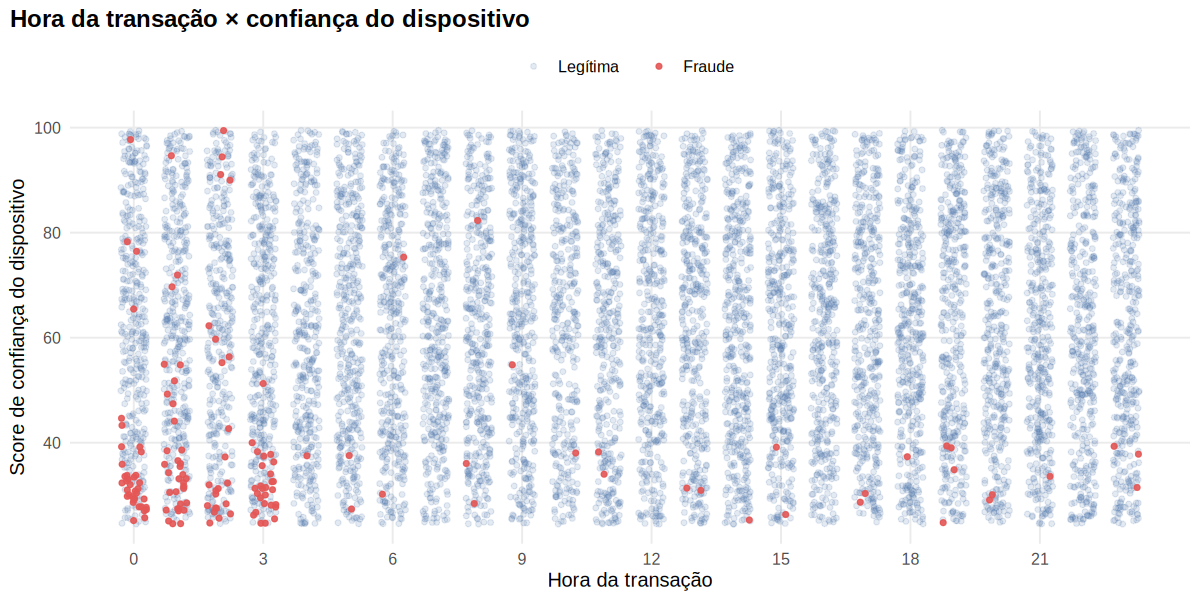

In [78]:
ordenado <- dados[order(dados$is_fraud), ]  # fraudes desenhadas por último

ggplot(ordenado, aes(transaction_hour, device_trust_score, color = is_fraud, alpha = is_fraud)) +
  geom_jitter(width = 0.3, height = 0.5, size = 1.3) +
  scale_color_manual(values = cores, name = NULL) +
  scale_alpha_manual(values = c("Legítima" = 0.15, "Fraude" = 0.9), name = NULL) +
  scale_x_continuous(breaks = seq(0, 23, 3)) +
  labs(title = "Hora da transação × confiança do dispositivo",
       x = "Hora da transação", y = "Score de confiança do dispositivo")

Cada ponto representa uma transação, e as fraudes estão destacadas em vermelho. É possível observar uma concentração de transações fraudulentas na região inferior esquerda do gráfico, que corresponde às operações realizadas na madrugada e com baixo score de confiança.

Entre as 364 transações realizadas entre 0h e 3h, com score abaixo de 40, aproximadamente 26% são fraudes. Esse percentual é bastante superior à taxa geral de fraude, de 1,51%.

Esse resultado sugere que a combinação de variáveis pode revelar padrões mais informativos para distinguir transações fraudulentas das legítimas do que a análise isolada de cada variável.

#### Correlação entre variáveis

Para que consigamos enxergar melhor como essas combinações de variáveis, citadas agora, atuam de modo a explicar características do alvo, podemos usar índices de correlação, como o de Spearman e o de Pearson, que usaremos.

In [ ]:
matriz <- dados[, numericas]
matriz$foreign_transaction <- as.integer(dados$foreign_transaction == "Sim")
matriz$location_mismatch <- as.integer(dados$location_mismatch == "Sim")
matriz$is_fraud <- as.integer(dados$is_fraud == "Fraude")

correlacao <- cor(matriz, method = "spearman")
round(correlacao, 2)

,amount,transaction_hour,device_trust_score,velocity_last_24h,cardholder_age,foreign_transaction,location_mismatch,is_fraud
amount,1.00,0.00,0.00,0.00,0.00,-0.01,0.01,0.01
transaction_hour,0.00,1.00,0.00,-0.01,0.01,0.00,0.00,-0.14
device_trust_score,0.00,0.00,1.00,0.00,0.01,0.01,0.00,-0.14
velocity_last_24h,0.00,-0.01,0.00,1.00,0.00,-0.01,-0.01,0.08
cardholder_age,0.00,0.01,0.01,0.00,1.00,0.01,0.01,0.00
foreign_transaction,-0.01,0.00,0.01,-0.01,0.01,1.00,0.00,0.19
location_mismatch,0.01,0.00,0.00,-0.01,0.01,0.00,1.00,0.17
is_fraud,0.01,-0.14,-0.14,0.08,0.00,0.19,0.17,1.00


Visualizando graficamente:

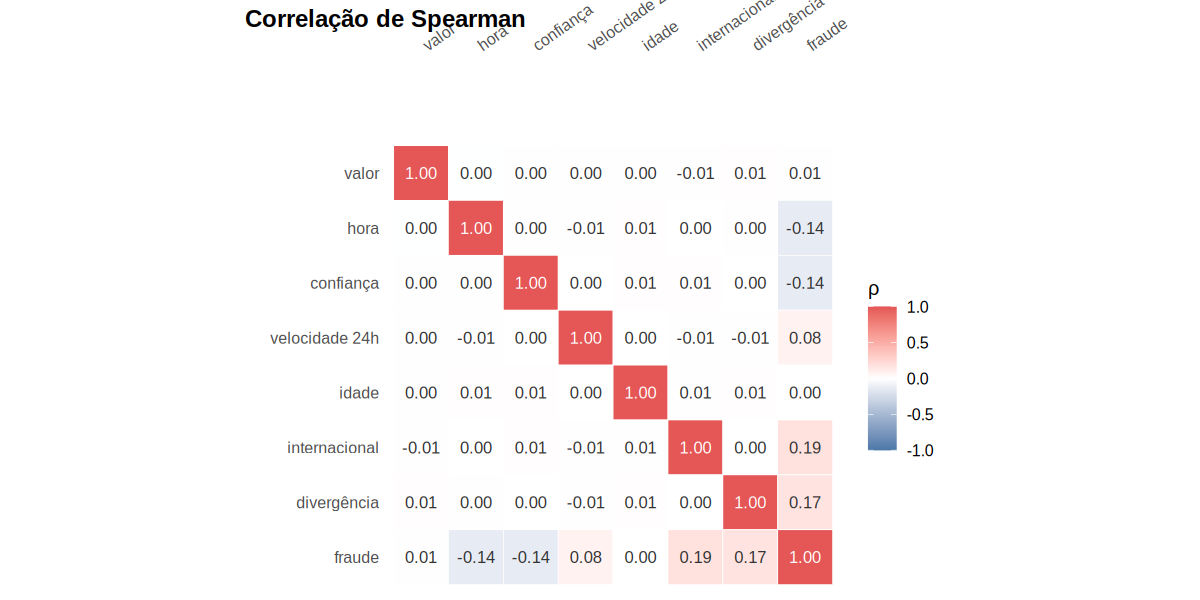

In [ ]:
nomes_curtos <- c(amount = "valor", transaction_hour = "hora", device_trust_score = "confiança",
                  velocity_last_24h = "velocidade 24h", cardholder_age = "idade",
                  foreign_transaction = "internacional", location_mismatch = "divergência",
                  is_fraud = "fraude")
ordem <- colnames(correlacao)
cor_long <- as.data.frame(as.table(correlacao))
names(cor_long) <- c("x", "y", "rho")
cor_long$x <- factor(cor_long$x, levels = ordem)
cor_long$y <- factor(cor_long$y, levels = rev(ordem))

ggplot(cor_long, aes(x, y, fill = rho)) +
  geom_tile(color = "white") +
  geom_text(aes(label = sprintf("%.2f", round(rho, 2) + 0), color = abs(rho) > 0.6), size = 3.5, show.legend = FALSE) +
  scale_color_manual(values = c("TRUE" = "white", "FALSE" = "#333333")) +
  scale_fill_gradient2(low = "#4C78A8", mid = "white", high = "#E45756", limits = c(-1, 1), name = "ρ") +
  scale_x_discrete(labels = nomes_curtos, position = "top") +
  scale_y_discrete(labels = nomes_curtos) +
  coord_fixed() +
  theme(axis.text.x = element_text(angle = 35, hjust = 0), panel.grid = element_blank(),
        legend.position = "right") +
  labs(title = "Correlação de Spearman", x = NULL, y = NULL)

As variáveis explicativas apresentam correlações praticamente nulas entre si (|ρ| ≤ 0,01), indicando que não há relações monotônicas relevantes entre elas. Em relação à fraude, as correlações também são relativamente baixas (0,19 para transações internacionais, 0,17 para divergência de localização, −0,14 para hora e score de confiança, e 0,08 para velocidade de transações).

Esses valores não contradizem as taxas de fraude observadas anteriormente. Como a fraude representa apenas 1,51% da base, mesmo diferenças expressivas entre grupos podem resultar em correlações baixas, o que gera um viés no entendimento desse gráfico.

Para resolver isso, podemos usar outras técnicas, como Information Value (IV), que mede o poder preditivo de uma variável em relação a um alvo binário desbalanceado, sem ser afetado pela proporção de fraudes. Vejamos:

In [ ]:
# install.packages("Information") # Não vem por padrão no kernel do Colab
library(Information)

dados_iv <- dados[, c(numericas, "foreign_transaction", "location_mismatch")]
dados_iv$is_fraud <- as.integer(dados$is_fraud == "Fraude")

IV_obj <- create_infotables(data = dados_iv, y = "is_fraud", bins = 10, parallel = FALSE)

tabela_iv <- IV_obj$Summary
tabela_iv$nome_amigavel <- ifelse(
  tabela_iv$Variable %in% names(nomes_curtos),
  nomes_curtos[tabela_iv$Variable],
  tabela_iv$Variable
)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependencies ‘plyr’, ‘iterators’, ‘doParallel’, ‘foreach’




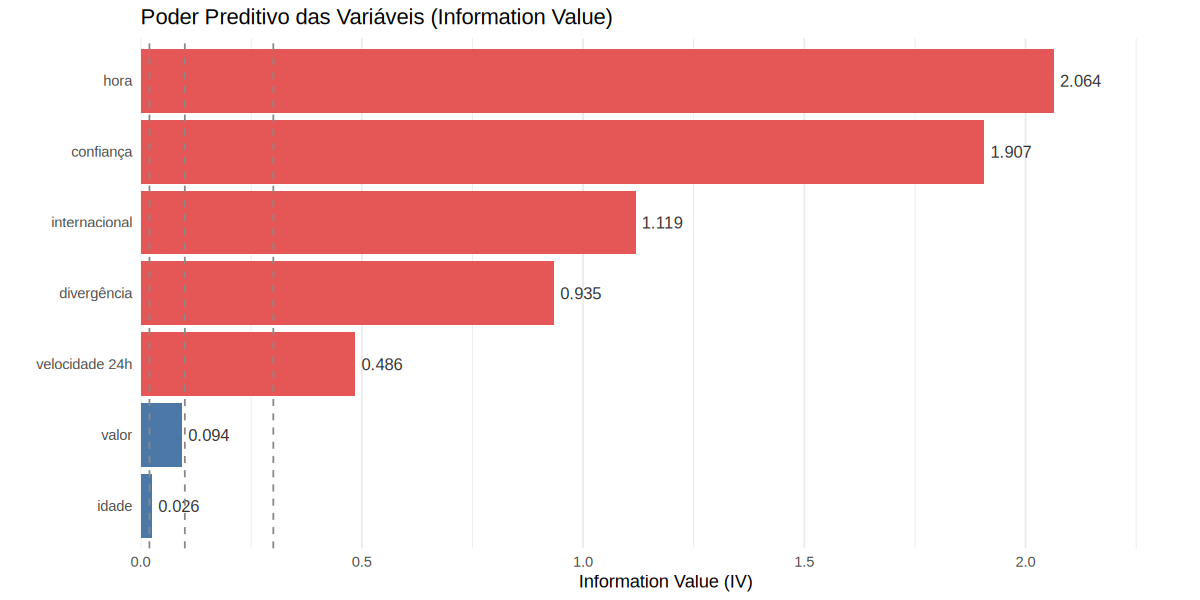

In [104]:
ggplot(tabela_iv, aes(x = reorder(nome_amigavel, IV), y = IV)) +
  geom_col(aes(fill = IV >= 0.1), show.legend = FALSE) +
  geom_text(aes(label = sprintf("%.3f", IV)), hjust = -0.15, size = 3.5, color = "#333333") +
  geom_hline(yintercept = c(0.02, 0.1, 0.3), linetype = "dashed", color = "#888888") +
  scale_fill_manual(values = c("TRUE" = "#E45756", "FALSE" = "#4C78A8")) +
  scale_y_continuous(expand = expansion(mult = c(0, 0.15))) +
  coord_flip() +
  theme_minimal() +
  theme(panel.grid.major.y = element_blank()) +
  labs(
    title = "Poder Preditivo das Variáveis (Information Value)",
    x = NULL,
    y = "Information Value (IV)"
  )

### 2.4 Insights e foco da validação

**REVISAR**

- **Desbalanceamento:** apenas 1,51% das transações são fraudes, o que exige métricas como recall, precisão e PR-AUC.
- **Indicadores binários:** a taxa de fraude é 8,38% nas transações internacionais (0,76% nas nacionais) e 8,40% com divergência de localização (0,86% sem divergência).
- **Score e velocidade:** a mediana do score é 32 nas fraudes e 62 nas legítimas; a mediana de transações em 24 h é 3 contra 2.
- **Horário:** as fraudes se concentram de 0 h a 3 h (7,32% contra 0,36% no restante). Como o recorte foi definido depois de ver os dados, é um achado **exploratório**, sem teste confirmatório abaixo.
- **Valor, idade e categoria:** `amount` tem cauda longa e comportamento ambíguo (média maior nas fraudes, mediana menor); idade e categoria quase não diferenciam as classes.
- **Variáveis mais promissoras para a modelagem:** `foreign_transaction`, `location_mismatch`, `device_trust_score`, `transaction_hour` e `velocity_last_24h`.
- **Hipótese inicial e próximas perguntas:** a EDA mostra que as variáveis carregam sinal sobre a fraude, mas só a modelagem dirá se os ensembles superam os modelos isolados. Surge também a pergunta de como lidar com o desbalanceamento no treino (estratificação, pesos ou reamostragem).

Essas associações sugerem variáveis úteis para a modelagem, sem demonstrar que uma delas causa fraude. Como os dados são simulados, os padrões podem refletir as regras usadas na geração.

## Validação Estatística

### 3.1 Hipóteses e plano de testes

Adotamos **α = 0,05** e quatro comparações, escolhidas pelos padrões da EDA. Para `foreign_transaction` e `location_mismatch`, a hipótese nula é independência entre o indicador e a classe; a alternativa é associação. Para `device_trust_score` e `velocity_last_24h`, a hipótese nula é igualdade das distribuições entre fraudes e legítimas; a alternativa é diferença. Os testes são **bicaudais**. Usamos Fisher exato nas tabelas 2×2, apropriado também quando há contagens pequenas, e Mann–Whitney/Wilcoxon para variáveis numéricas/discretas sem pressupor normalidade. Como existem empates, a aproximação assintótica é usada no teste de Wilcoxon. Ajustamos os quatro p-valores pelo método de Holm para controlar o erro familiar.

As transações são tratadas como observações independentes; o CSV não fornece identificador de cliente/cartão para conferir essa suposição. O teste de Wilcoxon compara distribuições, e só pode ser interpretado estritamente como teste de deslocamento de medianas sob formas de distribuição comparáveis.

#### Execução dos testes

In [81]:
legitimas <- dados$is_fraud == "Legítima"
fraudes <- dados$is_fraud == "Fraude"

# Numéricas: Mann–Whitney (Wilcoxon de duas amostras); binárias: Fisher exato
teste_score <- wilcox.test(dados$device_trust_score[fraudes], dados$device_trust_score[legitimas],
                           alternative = "two.sided", exact = FALSE)
teste_velocidade <- wilcox.test(dados$velocity_last_24h[fraudes], dados$velocity_last_24h[legitimas],
                                alternative = "two.sided", exact = FALSE)
teste_internacional <- fisher.test(table(dados$foreign_transaction, dados$is_fraud))
teste_localizacao <- fisher.test(table(dados$location_mismatch, dados$is_fraud))

#### Resultados

In [82]:
p_bruto <- c(teste_score$p.value, teste_velocidade$p.value,
             teste_internacional$p.value, teste_localizacao$p.value)
p_holm <- p.adjust(p_bruto, method = "holm")

resultado <- data.frame(
  hipotese = c("device_trust_score", "velocity_last_24h", "foreign_transaction", "location_mismatch"),
  teste = c("Mann–Whitney", "Mann–Whitney", "Fisher exato", "Fisher exato"),
  p_bruto = format(p_bruto, scientific = TRUE, digits = 3),
  p_holm = format(p_holm, scientific = TRUE, digits = 3),
  rejeita_H0 = ifelse(p_holm < 0.05, "Sim", "Não")
)
resultado

hipotese,teste,p_bruto,p_holm,rejeita_H0
<chr>,<chr>,<chr>,<chr>,<chr>
device_trust_score,Mann–Whitney,2.54e-43,7.62e-43,Sim
velocity_last_24h,Mann–Whitney,8.88e-15,8.88e-15,Sim
foreign_transaction,Fisher exato,1.12e-43,4.49e-43,Sim
location_mismatch,Fisher exato,2.27e-37,4.53e-37,Sim


In [83]:
odds <- data.frame(
  indicador = c("foreign_transaction", "location_mismatch"),
  odds_ratio = c(teste_internacional$estimate, teste_localizacao$estimate),
  ic_inf = c(teste_internacional$conf.int[1], teste_localizacao$conf.int[1]),
  ic_sup = c(teste_internacional$conf.int[2], teste_localizacao$conf.int[2]),
  row.names = NULL
)
odds[-1] <- round(odds[-1], 2)
odds

indicador,odds_ratio,ic_inf,ic_sup
<chr>,<dbl>,<dbl>,<dbl>
foreign_transaction,11.87,8.45,16.72
location_mismatch,10.52,7.47,14.79


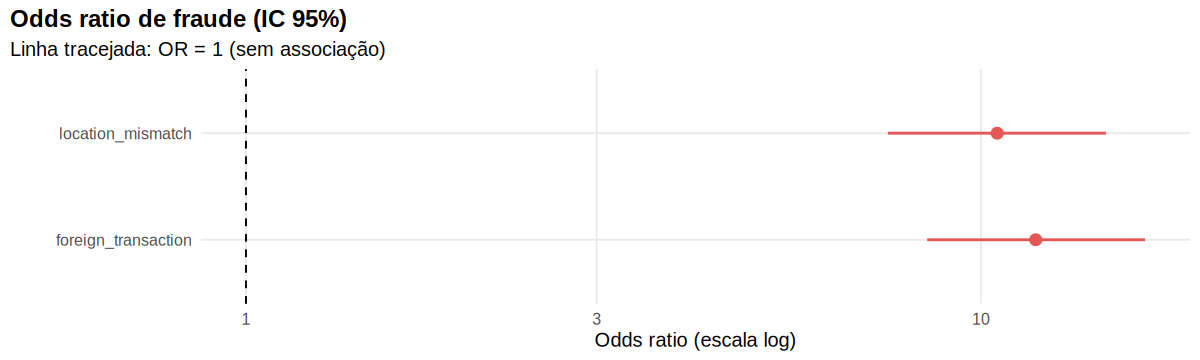

In [84]:
options(repr.plot.height = 3)  # gráfico baixo, só duas linhas

ggplot(odds, aes(odds_ratio, indicador)) +
  geom_vline(xintercept = 1, linetype = "dashed") +
  geom_pointrange(aes(xmin = ic_inf, xmax = ic_sup), color = "#E45756", linewidth = 0.8) +
  scale_x_log10() +
  labs(title = "Odds ratio de fraude (IC 95%)", subtitle = "Linha tracejada: OR = 1 (sem associação)",
       x = "Odds ratio (escala log)", y = NULL)

options(repr.plot.height = 5)

### 3.2–3.3 Resultados e interpretação

Uma checagem independente do CSV encontrou p-valores extremamente pequenos nas quatro comparações, inclusive após Holm (todos **p ajustados < 10⁻¹⁴**). O código acima calcula os valores com R; pequenas diferenças numéricas entre programas podem ocorrer pela aproximação do Wilcoxon. Há evidência contra as quatro hipóteses nulas a 5%. O sentido das associações vem das taxas e medianas na EDA: fraudes aparecem mais entre transações internacionais e com divergência de localização, junto com score menor e velocidade maior. Os odds ratios amostrais para internacional e divergência são cerca de **11,9** e **10,5**, respectivamente; odds não são probabilidades e essas associações não implicam causalidade.

Como os mesmos dados serviram para **selecionar** as hipóteses após a EDA e para testá-las, os p-valores são uma verificação interna, não confirmação externa. A etapa seguinte do projeto deve avaliar os modelos em dados separados, com divisão estratificada e métricas adequadas à classe rara (recall, precisão e PR-AUC), evitando usar informação do teste no treinamento.

## Pré processamento dos dados

## Modelagem e aplicação do ensemble

## Resultados obtidos

## Conclusão